# 01 · CUAD v1: know the data before fine-tuning

**Goal:** understand the Contract Understanding Atticus Dataset (CUAD) v1 well enough to design the
fine-tuning task, the chunking, the category subset and the train/test split *before* writing any training code.

**Dataset:** CUAD v1, The Atticus Project. Zenodo record 4595826 (DOI 10.5281/zenodo.4595826), CC BY 4.0.
Paper: Hendrycks et al., *CUAD: An Expert-Annotated NLP Dataset for Legal Contract Review*, NeurIPS 2021 (arXiv:2103.06268).

**Kernel:** `Python (track-b-slm)`, which is the `02_slm_finetuning/.venv`. The notebook reads only from `data/raw/` and writes nothing.

| Step | Question it answers |
|---|---|
| 1 | Is the download intact? What files are there? |
| 2 | How is the QA JSON structured? |
| 3 | What do the 41 categories mean? |
| 4 | How long are the contracts, what types are they, and how clean is the text? |
| 5 | How often does each category appear? (class balance) |
| 6 | How long are the labeled spans? |
| 7 | Where in a contract does each clause usually appear? |
| 8 | Are the labels internally consistent? (integrity checks) |
| 9 | What do the normalized answers in `master_clauses.csv` look like? |
| 10 | What happens when we chunk contracts for a 7B model? |
| 11 | Which categories should we fine-tune on? |
| 12 | Does a contract-level split leave enough positives in test? |

In [1]:
import ast, csv, difflib, hashlib, json, re, unicodedata
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 60)

# Locate the Track B root (the folder holding CLAUDE.md and data/), whether the kernel starts in notebooks/ or at the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists() and (p / "data").exists())
RAW  = ROOT / "data/raw/cuad_v1"
DATA = RAW / "CUAD_v1"

# Chart styling: one hue for single-series charts, orange only to highlight the candidate subset, muted grey otherwise
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b2"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
print("ROOT:", ROOT)

ROOT: /Users/alok/Documents/01_projects/11_self/08_challenge_ava/02_slm_finetuning


## Step 1: Integrity and inventory
Check the zip against the md5 that Zenodo publishes, then list what was extracted.

In [2]:
EXPECTED_MD5 = "c38f490a984420b8a62600db401fafd5"   # from https://zenodo.org/api/records/4595826
h = hashlib.md5()
with open(RAW / "CUAD_v1.zip", "rb") as f:
    for block in iter(lambda: f.read(1 << 20), b""):
        h.update(block)
print("md5 OK" if h.hexdigest() == EXPECTED_MD5 else f"MD5 MISMATCH: {h.hexdigest()}")

inv = []
for p in sorted(DATA.iterdir()):
    files = [p] if p.is_file() else [q for q in p.rglob("*") if q.is_file()]
    inv.append({"item": p.name + ("/" if p.is_dir() else ""), "files": len(files),
                "size_MB": round(sum(q.stat().st_size for q in files) / 1e6, 1)})
pd.DataFrame(inv)

md5 OK


,item,files,size_MB
0,CUAD_v1.json,1,40.1
1,CUAD_v1_README.txt,1,0.0
2,full_contract_pdf/,510,101.2
3,full_contract_txt/,510,26.8
4,label_group_xlsx/,28,1.6
5,master_clauses.csv,1,4.0


## Step 2: Structure of `CUAD_v1.json` (SQuAD 2.0 format)
`data → [contract] → paragraphs → [ {context, qas → [ {question, id, answers, is_impossible} ]} ]`

In [4]:
raw = json.load(open(DATA / "CUAD_v1.json", encoding="utf-8"))
print("top-level keys :", list(raw))
print("version        :", raw["version"])
print("contracts      :", len(raw["data"]))
print("paragraphs/contract:", Counter(len(d["paragraphs"]) for d in raw["data"]))  # 1 means the whole contract is a single context
doc = raw["data"][0]
print("contract keys  :", list(doc), "| paragraph keys:", list(doc["paragraphs"][0]))
qa = doc["paragraphs"][0]["qas"][3]
print("\nOne QA record:")
print(json.dumps({**qa, "answers": qa["answers"][:2]}, indent=2)[:1200])

top-level keys : ['version', 'data']
version        : aok_v1.0
contracts      : 510
paragraphs/contract: Counter({1: 510})
contract keys  : ['title', 'paragraphs'] | paragraph keys: ['qas', 'context']

One QA record:
{
  "answers": [
    {
      "text": "The term of this  Agreement  shall be ten (10)                            years (the \"Term\")  which shall  commence on the date                            upon which the Company  delivers to  Distributor  the                            last Sample, as defined  hereinafter.",
      "answer_start": 5268
    },
    {
      "text": "Unless  earlier   terminated   otherwise  provided                   therein,  this  Agreement,  subject to the  commencement  date                   established  in Section 1.3,  shall be effective  immediately.",
      "answer_start": 31058
    }
  ],
  "id": "LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Effective Date",
  "question": "Highlight the parts (if any) of this contract related to \"Effec

In [5]:
# Flatten into three tidy tables: contracts, questions (contract x category), spans
contracts, questions, spans = [], [], []
for d in raw["data"]:
    p = d["paragraphs"][0]
    ctx = p["context"]
    contracts.append({"contract": d["title"], "text": ctx, "n_chars": len(ctx)})
    for q in p["qas"]:
        cat = q["id"].split("__")[-1]
        questions.append({"contract": d["title"], "category": cat, "question": q["question"],
                          "is_impossible": q.get("is_impossible"), "n_spans": len(q["answers"])})
        for a in q["answers"]:
            s = a["answer_start"]
            spans.append({"contract": d["title"], "category": cat, "text": a["text"],
                          "start": s, "end": s + len(a["text"]), "n_chars": len(a["text"])})

C = pd.DataFrame(contracts)
Q = pd.DataFrame(questions)
S = pd.DataFrame(spans)
CATS = sorted(Q.category.unique())
print(f"contracts={len(C)}  questions={len(Q)}  categories={len(CATS)}  spans={len(S)}")
print(f"questions with >=1 span: {(Q.n_spans > 0).sum()}  |  'no answer' questions: {(Q.n_spans == 0).sum()} "
      f"({(Q.n_spans == 0).mean():.0%})")

contracts=510  questions=20910  categories=41  spans=13823
questions with >=1 span: 6702  |  'no answer' questions: 14208 (68%)


## Step 3: What each category means
Every question follows one template: *Highlight the parts (if any) of this contract related to "X" that should be
reviewed by a lawyer. Details: …*. The **Details** text is the annotation guideline for that category. It is the
closest thing to a label definition, and we can reuse it in the fine-tuning prompt.

In [6]:
defs = (Q.drop_duplicates("category")
          .assign(definition=lambda x: x.question.str.split("Details:", n=1).str[1].str.strip())
          [["category", "definition"]].sort_values("category").reset_index(drop=True))
defs

,category,definition
0,Affiliate License-Licensee,Does the contract contain a license grant to a licensee (incl. sublicensor) and the affiliates of such lic...
1,Affiliate License-Licensor,Does the contract contain a license grant by affiliates of the licensor or that includes intellectual prop...
2,Agreement Date,The date of the contract
3,Anti-Assignment,Is consent or notice required of a party if the contract is assigned to a third party?
4,Audit Rights,"Does a party have the right to audit the books, records, or physical locations of the counterparty to ens..."
5,Cap On Liability,Does the contract include a cap on liability upon the breach of a party’s obligation? This includes time l...
6,Change Of Control,Does one party have the right to terminate or is consent or notice required of the counterparty if such pa...
7,Competitive Restriction Exception,"This category includes the exceptions or carveouts to Non-Compete, Exclusivity and No-Solicit of Customers..."
8,Covenant Not To Sue,Is a party restricted from contesting the validity of the counterparty’s ownership of intellectual propert...
9,Document Name,The name of the contract


## Step 4: The contracts
### 4a · Length
Token counts here are **approximate** (characters / 4, a common rule of thumb for English with BPE tokenizers).
We will re-measure with the real tokenizer once the base model is chosen.

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
approx tokens,510.0,13141.0,13987.0,161.0,1596.0,4104.0,8286.0,16599.0,30529.0,40623.0,67874.0,84553.0


contracts longer than  2,000 tokens: 88.8%
contracts longer than  4,000 tokens: 75.5%
contracts longer than  8,000 tokens: 52.0%
contracts longer than 16,000 tokens: 25.9%
contracts longer than 32,000 tokens:  9.6%


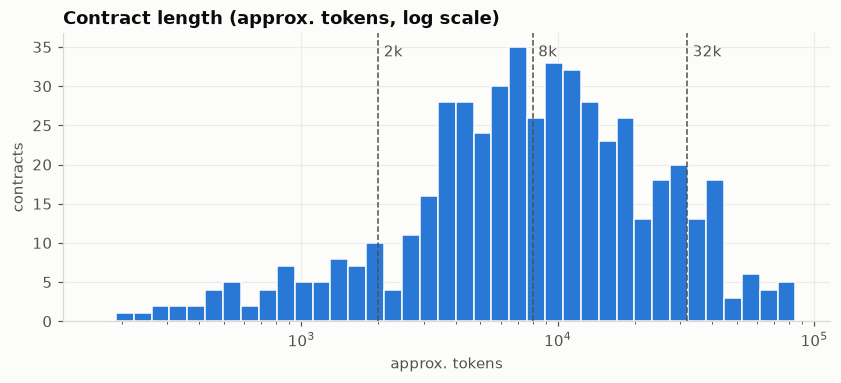

In [7]:
C["approx_tokens"] = C.n_chars / 4
pct = C.approx_tokens.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(0)
display(pct.to_frame("approx tokens").T)

for limit in [2_000, 4_000, 8_000, 16_000, 32_000]:
    print(f"contracts longer than {limit:>6,} tokens: {(C.approx_tokens > limit).mean():5.1%}")

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(np.log10(C.approx_tokens.min()), np.log10(C.approx_tokens.max()), 40)
ax.hist(C.approx_tokens, bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log")
for v, lab in [(2_000, "2k"), (8_000, "8k"), (32_000, "32k")]:
    ax.axvline(v, color=INK2, lw=1, ls="--"); ax.text(v * 1.05, ax.get_ylim()[1] * .92, lab, color=INK2)
ax.set_title("Contract length (approx. tokens, log scale)"); ax.set_xlabel("approx. tokens"); ax.set_ylabel("contracts")
plt.show()

### 4b · Contract types
The contract type is not in the JSON. It is encoded in the PDF folder structure (`full_contract_pdf/Part_*/<Type>/`).
File names differ slightly between the JSON, the PDFs and the CSV (accents, trailing spaces, punctuation), so we join on a
normalized key with a fuzzy fallback and **report the join rate**. That rate is itself a data-quality finding.

type join: {'exact': 509, 'fuzzy': 1}


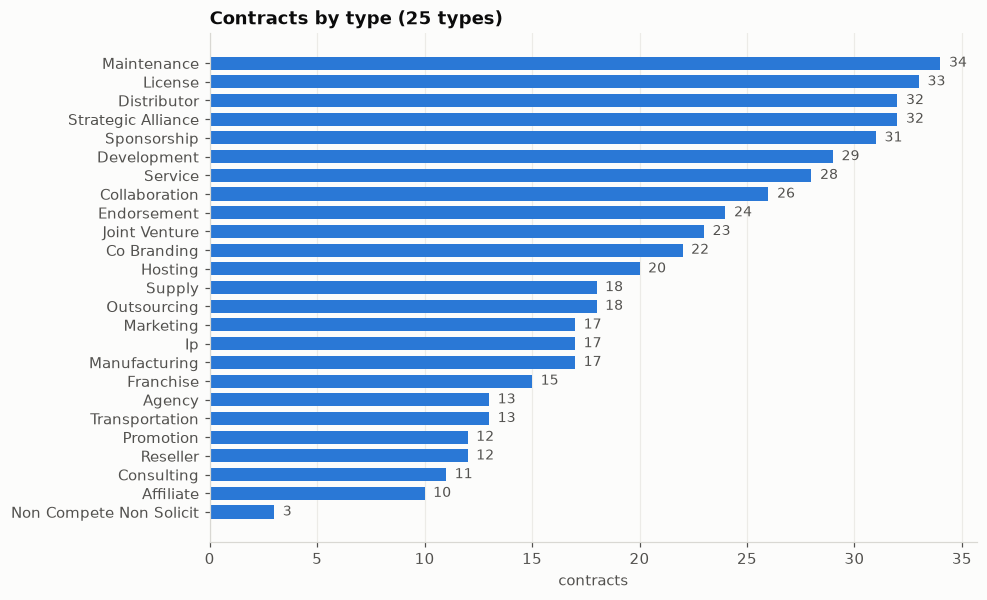

supplier-relevant types: 172 contracts {'Maintenance': 34, 'Distributor': 32, 'Service': 28, 'Supply': 18, 'Outsourcing': 18, 'Manufacturing': 17, 'Transportation': 13, 'Reseller': 12}


In [8]:
def norm_key(s: str) -> str:
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", s.casefold())

def norm_type(folder: str) -> str:
    t = folder.replace("_", " ")
    t = re.sub(r"\b(Agreements?|Filing)\b", "", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip(" -").title()

pdf_type = {}
for p in (DATA / "full_contract_pdf").rglob("*"):
    if p.is_file() and p.suffix.lower() == ".pdf":
        pdf_type[norm_key(p.stem)] = norm_type(p.relative_to(DATA / "full_contract_pdf").parts[1])

def lookup(title, table):
    k = norm_key(title)
    if k in table:
        return table[k], "exact"
    m = difflib.get_close_matches(k, table.keys(), n=1, cutoff=0.9)
    return (table[m[0]], "fuzzy") if m else (None, "missing")

C[["type", "type_join"]] = C.contract.apply(lambda t: pd.Series(lookup(t, pdf_type)))
print("type join:", C.type_join.value_counts().to_dict())
type_counts = C.type.value_counts()

fig, ax = plt.subplots(figsize=(9, 6))
tc = type_counts.sort_values()
ax.barh(tc.index, tc.values, color=BLUE, height=0.7)
for y, v in enumerate(tc.values):
    ax.text(v + 0.4, y, str(v), va="center", color=INK2, fontsize=9)
ax.set_title(f"Contracts by type ({C.type.nunique()} types)"); ax.set_xlabel("contracts"); ax.grid(axis="y", visible=False)
plt.show()

SUPPLY_LIKE = ["Supply", "Manufacturing", "Distributor", "Outsourcing", "Transportation", "Reseller", "Maintenance", "Service"]
print("supplier-relevant types:", int(C.type.isin(SUPPLY_LIKE).sum()), "contracts", C[C.type.isin(SUPPLY_LIKE)].type.value_counts().to_dict())

In [9]:
# Median length by type: are some types systematically longer?
(C.groupby("type").approx_tokens.agg(["count", "median", "max"]).round(0)
   .sort_values("median", ascending=False).astype(int))

,count,median,max
type,,,
Agency,13,30390,40406
Franchise,15,29218,75192
Promotion,12,16004,43895
Ip,17,14127,38866
Supply,18,13953,47168
Collaboration,26,12544,83820
Outsourcing,18,12340,84553
Transportation,13,12304,57418
Co Branding,22,11585,28690


### 4c · Read one contract, then measure text noise
The text was extracted from PDFs. Before trusting it, look at a real one and count the usual PDF artifacts.

In [9]:
ex = C[C.type == "Supply"].sort_values("n_chars").iloc[len(C[C.type == "Supply"]) // 2]   # a median-length Supply agreement
print(ex.contract, f"| {ex.n_chars:,} chars | ~{ex.approx_tokens:,.0f} tokens\n" + "-" * 100)
print(ex.text[:2500])

ReynoldsConsumerProductsInc_20191115_S-1_EX-10.18_11896469_EX-10.18_Supply Agreement | 61,710 chars | ~15,428 tokens
----------------------------------------------------------------------------------------------------
Exhibit 10.18

MASTER SUPPLY AGREEMENT

MASTER SUPPLY AGREEMENT (the "Agreement") dated November 1, 2019 (the "Effective Date") between REYNOLDS CONSUMER PRODUCTS LLC, a Delaware limited liability company with its headquarters at 1900 West Field Court, Lake Forest, IL 60045 ("Seller"), and PACTIV LLC, a Delaware limited liability company with its headquarters at 1900 West Field Court, Lake Forest, IL 60045 ("Buyer"). Seller and Buyer are referred to individually at times as a "Party" and collectively at times as the "Parties".

BACKGROUND

A. Seller sells various types of products used in the consumer and food service markets.

B. Buyer sells various types of products, including certain products of the type made by Seller, to its customers.

C. The Parties are entering in

In [10]:
NOISE = {
    "redaction [***] / [*]":   r"\[\s*\*+\s*\]",
    "'Source: <company> ...' page header": r"Source:\s+\S+.*?(10-K|10-Q|8-K|S-1)",
    "page markers (Page x / -x-)": r"(?im)^\s*(page\s+\d+(\s+of\s+\d+)?|-\s*\d+\s*-)\s*$",
    "runs of 3+ blank lines":  r"\n\s*\n\s*\n\s*\n",
    "non-ASCII characters":    r"[^\x00-\x7f]",
}
rows = []
for name, pat in NOISE.items():
    hits = C.text.str.count(pat)
    rows.append({"artifact": name, "contracts_affected": f"{(hits > 0).mean():.0%}", "median_hits_when_present": int(hits[hits > 0].median()) if (hits > 0).any() else 0})
pd.DataFrame(rows)

,artifact,contracts_affected,median_hits_when_present
0,redaction [***] / [*],22%,32
1,'Source: <company> ...' page header,27%,11
2,page markers (Page x / -x-),14%,12
3,runs of 3+ blank lines,97%,12
4,non-ASCII characters,41%,8


## Step 5: Class balance (how often each category appears)
This is the most important table for picking categories. The **contracts** column counts contracts with at least one span;
**spans/contract** is how many separate spans a contract has when the category is present.

In [11]:
support = (S.groupby("category")
             .agg(contracts=("contract", "nunique"), spans=("text", "size"),
                  med_span_chars=("n_chars", "median"), p90_span_chars=("n_chars", lambda x: x.quantile(.9)))
             .reindex(CATS).fillna(0))
support["pct_contracts"] = support.contracts / len(C)
support["spans_per_contract"] = support.spans / support.contracts.replace(0, np.nan)
support = support.sort_values("contracts", ascending=False)
support.style.format({"pct_contracts": "{:.0%}", "spans_per_contract": "{:.1f}", "med_span_chars": "{:.0f}",
                      "p90_span_chars": "{:.0f}", "contracts": "{:.0f}", "spans": "{:.0f}"}).bar(subset=["pct_contracts"], color="#cde2fb")

,contracts,spans,med_span_chars,p90_span_chars,pct_contracts,spans_per_contract
category,,,,,,
Document Name,510,521,25,47,100%,1.0
Parties,509,2554,17,44,100%,5.0
Agreement Date,470,476,16,26,92%,1.0
Governing Law,437,464,178,331,86%,1.1
Expiration Date,413,467,195,408,81%,1.1
Effective Date,390,447,20,186,76%,1.1
Anti-Assignment,374,654,218,585,73%,1.7
Cap On Liability,275,672,306,705,54%,2.4
License Grant,255,777,356,758,50%,3.0


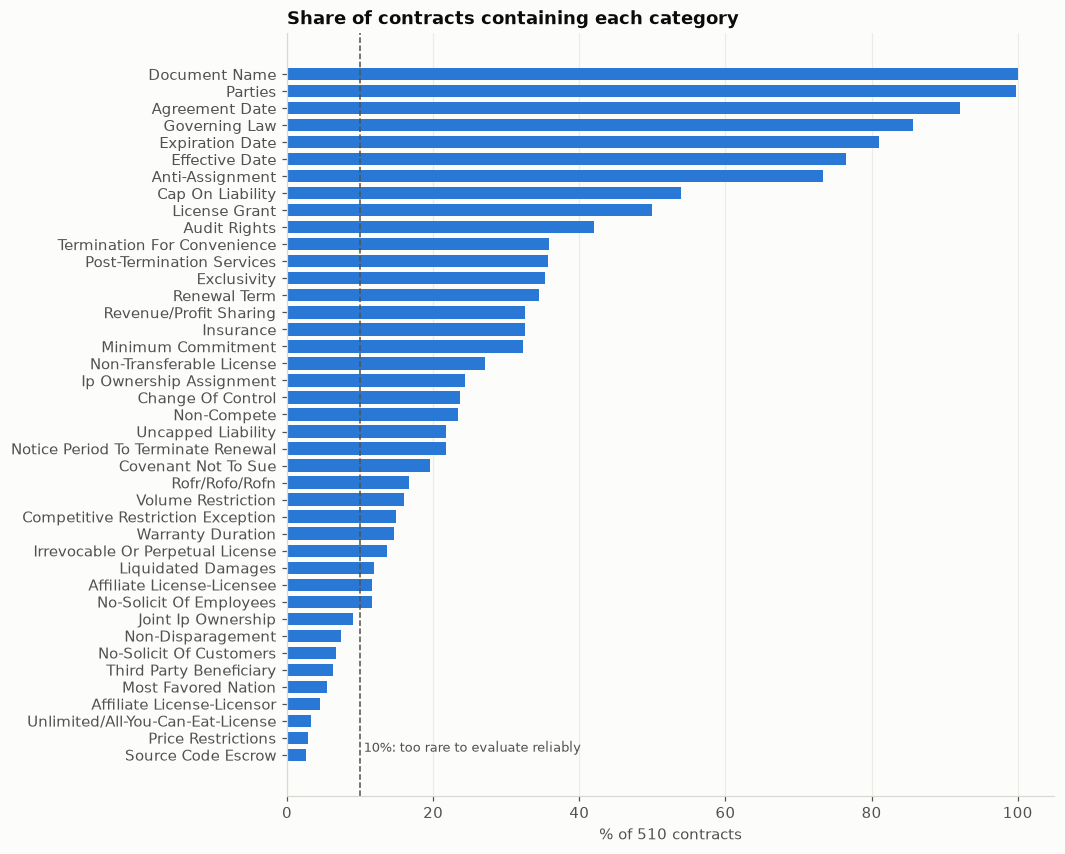

categories present in <10% of contracts: ['Joint Ip Ownership', 'Non-Disparagement', 'No-Solicit Of Customers', 'Third Party Beneficiary', 'Most Favored Nation', 'Affiliate License-Licensor', 'Unlimited/All-You-Can-Eat-License', 'Price Restrictions', 'Source Code Escrow']


In [12]:
fig, ax = plt.subplots(figsize=(9, 9))
s = support.pct_contracts.sort_values()
ax.barh(s.index, s.values * 100, color=BLUE, height=0.72)
ax.axvline(10, color=INK2, ls="--", lw=1); ax.text(10.5, 0, "10%: too rare to evaluate reliably", color=INK2, fontsize=8.5, va="bottom")
ax.set_title("Share of contracts containing each category"); ax.set_xlabel("% of 510 contracts"); ax.grid(axis="y", visible=False)
plt.show()
print("categories present in <10% of contracts:", list(support[support.pct_contracts < .10].index))

## Step 6: Span lengths
Short spans (dates, names) and long spans (whole clauses) are different sub-tasks. Long spans also set a **lower bound on
chunk size**: a span longer than the chunk can never be extracted whole.

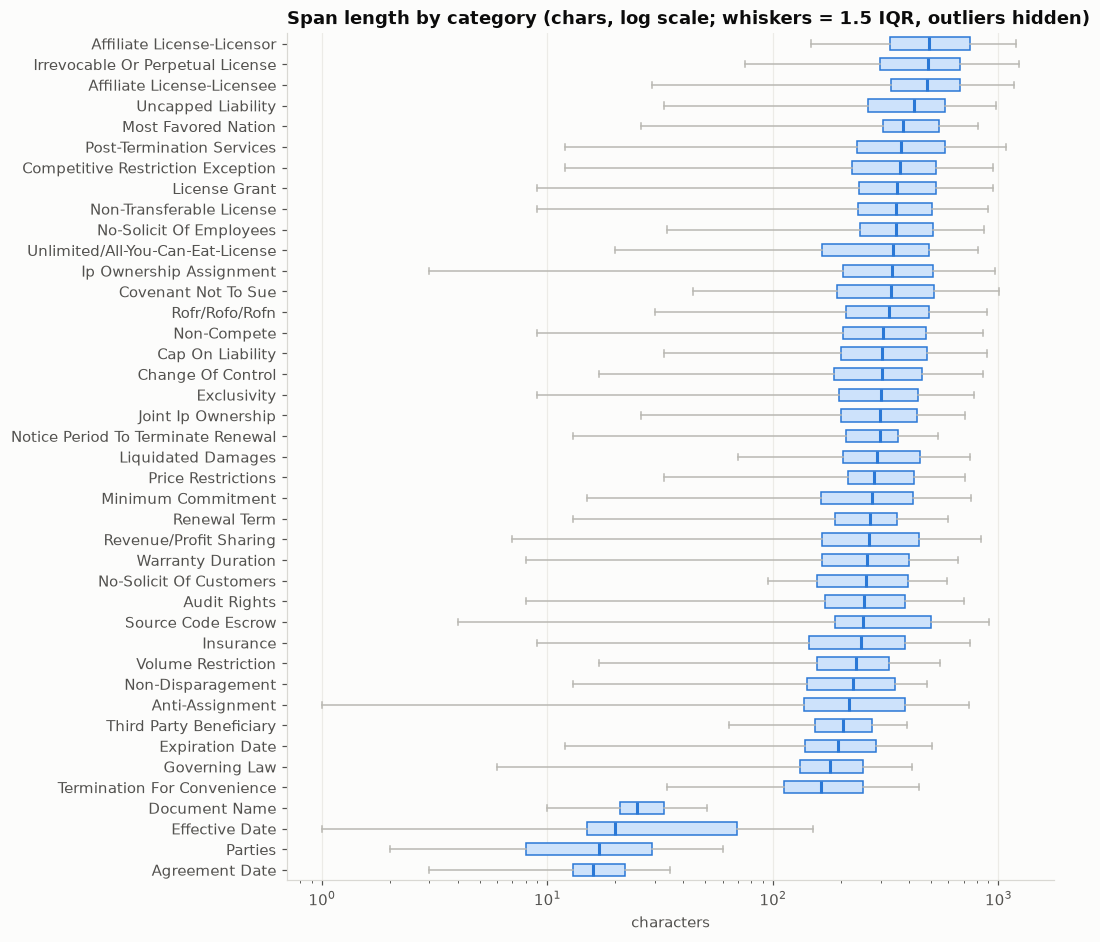

spans longer than 1,000 chars (~250 tok):  348  (2.52%)
spans longer than 2,000 chars (~500 tok):   35  (0.25%)
spans longer than 4,000 chars (~1,000 tok):    0  (0.00%)
spans longer than 6,000 chars (~1,500 tok):    0  (0.00%)

Longest spans:


,category,n_chars,contract
9269,Source Code Escrow,3884,HEALTHGATEDATACORP_11_24_1999-EX-10.1-HOSTING AND MANAGEMENT AGREEMENT - Escrow Agreement
4552,Minimum Commitment,3546,SUMMAFOURINC_06_19_1998-EX-10.3-SOFTWARE LICENSE AND MAINTENANCE AGREEMENT
9271,Source Code Escrow,3393,HEALTHGATEDATACORP_11_24_1999-EX-10.1-HOSTING AND MANAGEMENT AGREEMENT - Escrow Agreement
4547,Minimum Commitment,3043,SUMMAFOURINC_06_19_1998-EX-10.3-SOFTWARE LICENSE AND MAINTENANCE AGREEMENT
12874,Competitive Restriction Exception,2820,"OPTIMIZEDTRANSPORTATIONMANAGEMENT,INC_07_26_2000-EX-6.6-DISTRIBUTOR AGREEMENT"


In [13]:
order = S.groupby("category").n_chars.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 10))
ax.boxplot([S.loc[S.category == c, "n_chars"] for c in order], orientation="horizontal", tick_labels=order, widths=0.6,
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY))
ax.set_xscale("log"); ax.set_title("Span length by category (chars, log scale; whiskers = 1.5 IQR, outliers hidden)")
ax.set_xlabel("characters"); ax.grid(axis="y", visible=False)
plt.show()
for lim in [1_000, 2_000, 4_000, 6_000]:
    print(f"spans longer than {lim:>5,} chars (~{lim//4:,} tok): {(S.n_chars > lim).sum():4d}  ({(S.n_chars > lim).mean():.2%})")
print("\nLongest spans:"); display(S.nlargest(5, "n_chars")[["category", "n_chars", "contract"]])

## Step 7: Where in a contract do clauses appear?
Relative position = span start / contract length (0 = first character, 1 = last). If a category always sits on the
first page, a model only ever sees it in chunk 0. That is a positional shortcut the model can learn and that may not generalize.

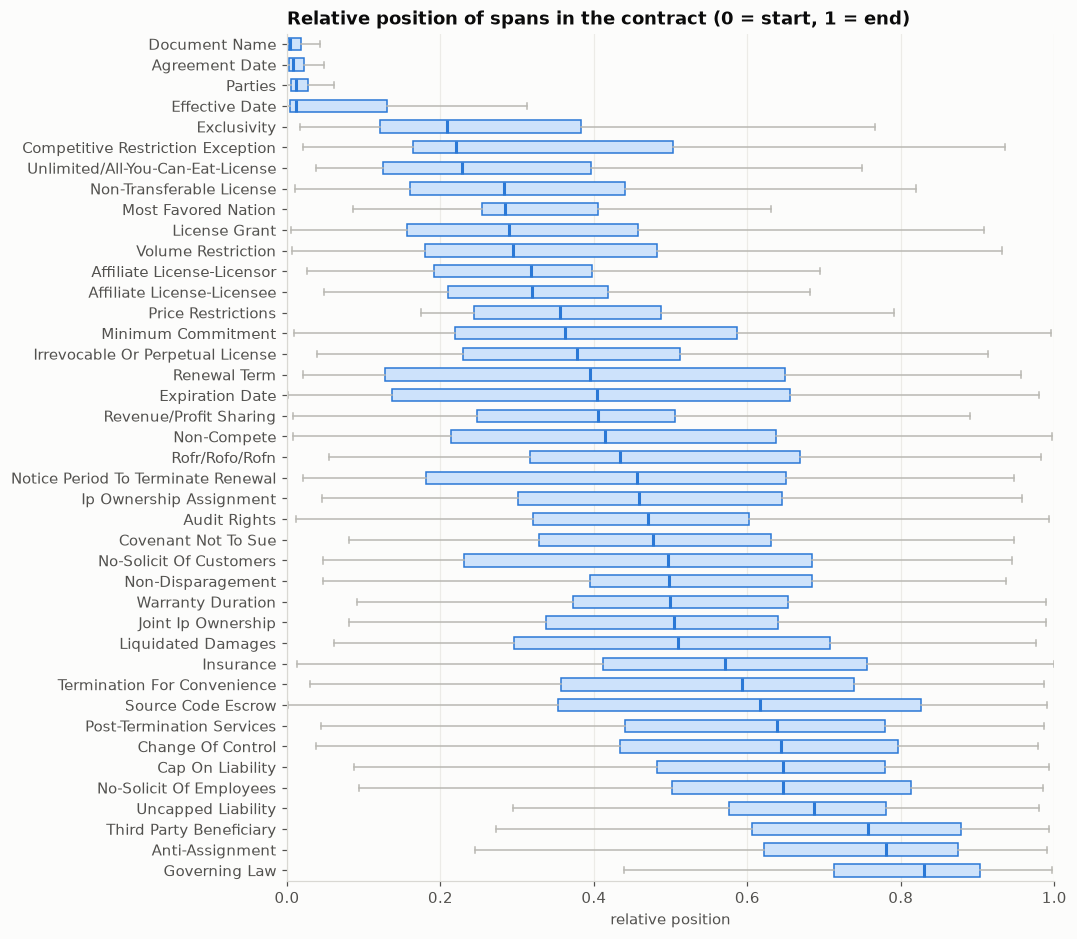

share of spans in the first 5% of the contract:
category
Document Name                         87%
Parties                               84%
Agreement Date                        83%
Effective Date                        64%
Notice Period To Terminate Renewal    10%
Renewal Term                          10%
Unlimited/All-You-Can-Eat-License      9%
Expiration Date                        8%


In [14]:
S["rel_pos"] = S.start / S.contract.map(C.set_index("contract").n_chars)
order = S.groupby("category").rel_pos.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 10))
ax.boxplot([S.loc[S.category == c, "rel_pos"] for c in order], orientation="horizontal", tick_labels=order, widths=0.6,
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY))
ax.set_xlim(0, 1); ax.set_title("Relative position of spans in the contract (0 = start, 1 = end)")
ax.set_xlabel("relative position"); ax.grid(axis="y", visible=False)
plt.show()
print("share of spans in the first 5% of the contract:")
print(S.assign(early=S.rel_pos < .05).groupby("category").early.mean().sort_values(ascending=False).head(8).map("{:.0%}".format).to_string())

## Step 8: Label integrity checks
Before training on labels, check that they say what we think they say.
1. Does `context[answer_start : answer_start+len]` equal the answer text? (offset alignment)
2. Is the JSON context identical to the `.txt` file?
3. Is `is_impossible` consistent with an empty answer list?
4. Are there duplicate spans?
5. Does the **same text get labeled with several categories**? (This matters for output design: one span can carry multiple labels.)

In [15]:
ctx = C.set_index("contract").text
S["aligned"] = [ctx[r.contract][r.start:r.end] == r.text for r in S.itertuples()]
print(f"1. offset alignment: {S.aligned.mean():.2%} aligned ({(~S.aligned).sum()} misaligned)")

txt_dir = DATA / "full_contract_txt"
txt_by_key = {norm_key(p.stem): p for p in txt_dir.glob("*.txt")}
same = missing = 0
for r in C.itertuples():
    p = txt_by_key.get(norm_key(r.contract))
    if p is None: missing += 1; continue
    same += p.read_text(encoding="utf-8", errors="replace") == r.text
print(f"2. JSON context == .txt file: {same}/{len(C) - missing} identical, {missing} without a matching .txt name")

bad = Q[(Q.is_impossible == True) & (Q.n_spans > 0) | (Q.is_impossible == False) & (Q.n_spans == 0)]
print(f"3. is_impossible inconsistent with answers: {len(bad)}")

dups = S.duplicated(["contract", "category", "start", "end"]).sum()
print(f"4. exact duplicate spans (same contract, category, offsets): {dups}")

1. offset alignment: 100.00% aligned (0 misaligned)
2. JSON context == .txt file: 510/510 identical, 0 without a matching .txt name
3. is_impossible inconsistent with answers: 0
4. exact duplicate spans (same contract, category, offsets): 0


In [16]:
# 5. Cross-category overlap: pairs of categories whose spans overlap in the same contract
pair_counts = Counter()
for _, g in S.groupby("contract"):
    rows = list(g[["category", "start", "end"]].itertuples(index=False))
    for a, b in combinations(rows, 2):
        if a.category != b.category and a.start < b.end and b.start < a.end:
            pair_counts[tuple(sorted((a.category, b.category)))] += 1
ov = pd.DataFrame([(a, b, n) for (a, b), n in pair_counts.most_common(15)], columns=["category A", "category B", "overlapping span pairs"])
print(f"{sum(pair_counts.values())} overlapping span pairs across {len(pair_counts)} category pairs. Top 15:")
ov

2122 overlapping span pairs across 181 category pairs. Top 15:

,category A,category B,overlapping span pairs
0,Agreement Date,Effective Date,265
1,License Grant,Non-Transferable License,216
2,Irrevocable Or Perpetual License,License Grant,155
3,Cap On Liability,Uncapped Liability,141
4,Exclusivity,License Grant,113
5,Notice Period To Terminate Renewal,Renewal Term,105
6,Affiliate License-Licensee,License Grant,74
7,Effective Date,Expiration Date,61
8,Affiliate License-Licensor,License Grant,48
9,Expiration Date,Renewal Term,46


## Step 9: `master_clauses.csv` and its normalized answers
One row per contract. For each category there is a span column (a Python-list string) and an `-Answer` column holding the
**normalized value**: Yes/No for flags, or a concrete value (a state, a date, a duration). These normalized values are a
possible second fine-tuning target (extract the span, then normalize it).

In [17]:
M = pd.read_csv(DATA / "master_clauses.csv", dtype=str, keep_default_na=False, encoding="utf-8", encoding_errors="replace")
print(M.shape)

def answer_col(cat):  # one header has a stray space ('... Renewal- Answer')
    return next(c for c in M.columns if c != cat and c.replace(" ", "").lower() == (cat + "-Answer").replace(" ", "").lower())

M_CATS = [c for c in M.columns if c != "Filename" and "answer" not in c.lower()]
print("categories in CSV:", len(M_CATS), "| same names as JSON:", set(M_CATS) == set(CATS))

kinds = []
for cat in M_CATS:
    v = M[answer_col(cat)].str.strip()
    yn = v.str.lower().isin(["yes", "no"])
    kinds.append({"category": cat, "answer_kind": "Yes/No" if yn.mean() > .95 else "value",
                  "empty": f"{(v == '').mean():.0%}", "distinct_values": v[v != ""].nunique(),
                  "examples": " | ".join(v[v != ""].value_counts().index[:4])})
K = pd.DataFrame(kinds).sort_values(["answer_kind", "category"]).reset_index(drop=True)
K

(510, 83)
categories in CSV: 41 | same names as JSON: True


,category,answer_kind,empty,distinct_values,examples
0,Affiliate License-Licensee,Yes/No,0%,2,No | Yes
1,Affiliate License-Licensor,Yes/No,0%,2,No | Yes
2,Anti-Assignment,Yes/No,0%,2,Yes | No
3,Audit Rights,Yes/No,0%,2,No | Yes
4,Cap On Liability,Yes/No,0%,2,Yes | No
5,Change Of Control,Yes/No,0%,2,No | Yes
6,Competitive Restriction Exception,Yes/No,0%,2,No | Yes
7,Covenant Not To Sue,Yes/No,0%,2,No | Yes
8,Exclusivity,Yes/No,0%,2,No | Yes
9,Insurance,Yes/No,0%,2,No | Yes


In [18]:
# Distributions of the value-type answers that matter for a supplier-contract review
for cat in ["Governing Law", "Renewal Term", "Notice Period To Terminate Renewal", "Expiration Date", "Agreement Date"]:
    v = M[answer_col(cat)].str.strip().replace("", "<empty>")
    print(f"\n{cat}  ({v.nunique()} distinct)")
    print(v.value_counts().head(8).to_string())


Governing Law  (78 distinct)
Governing Law-Answer
New York                      97
<empty>                       76
California                    55
Delaware                      40
Texas                         28
Florida                       17
Pennsylvania                  13
People's Republic of China    11

Renewal Term  (46 distinct)
Renewal Term-Answer
<empty>               347
successive 1 year      60
1 year                 11
perpetual               8
successive 5 years      8
3 years                 6
successive 2 years      6
2 years                 5

Notice Period To Terminate Renewal  (22 distinct)
Notice Period To Terminate Renewal- Answer
<empty>      409
30 days       26
90 days       16
60 days       15
6 months      13
180 days       5
12 months      4
120 days       4

Expiration Date  (250 distinct)
Expiration Date-Answer
<empty>      181
perpetual     61
Perpetual      5
12/31/06       4
12/31/20       3
[]/[]/[]       3
6/30/10        2
12/31/04       2

Agree

In [19]:
# Consistency: CSV spans vs JSON spans, and Yes/No vs presence of a span
M["key"] = M.Filename.map(lambda f: norm_key(Path(f).stem))
C["key"] = C.contract.map(norm_key)
key2contract = dict(zip(C.key, C.contract))
M["contract"] = M.key.map(key2contract)
fuzzy = M.contract.isna()
M.loc[fuzzy, "contract"] = M.loc[fuzzy, "key"].map(lambda k: (lambda m: key2contract[m[0]] if m else None)(difflib.get_close_matches(k, key2contract, n=1, cutoff=0.9)))
print(f"CSV rows joined to JSON contracts: {M.contract.notna().sum()}/{len(M)} ({fuzzy.sum()} needed fuzzy matching)")

json_spans = S.groupby(["contract", "category"]).text.apply(lambda x: sorted(t.strip() for t in x)).to_dict()
agree = yes_wo_span = span_wo_yes = total = 0
for _, r in M[M.contract.notna()].iterrows():
    for cat in M_CATS:
        try:
            csv_sp = sorted(t.strip() for t in ast.literal_eval(r[cat]))
        except (ValueError, SyntaxError):
            csv_sp = None
        js = json_spans.get((r.contract, cat), [])
        total += 1
        agree += csv_sp == js
        ans = r[answer_col(cat)].strip().lower()
        if ans == "yes" and not js: yes_wo_span += 1
        if ans == "no" and js: span_wo_yes += 1
print(f"CSV span list == JSON span list: {agree}/{total} ({agree/total:.1%})")
print(f"'Yes' but no JSON span: {yes_wo_span} | 'No' but JSON has a span: {span_wo_yes}")

CSV rows joined to JSON contracts: 510/510 (0 needed fuzzy matching)


CSV span list == JSON span list: 20299/20910 (97.1%)
'Yes' but no JSON span: 2 | 'No' but JSON has a span: 0


In [20]:
# Why do about 3% disagree? Classify the mismatches and show one
omitted = Counter()
example = None
for _, r in M[M.contract.notna()].iterrows():
    for cat in M_CATS:
        csv_sp = sorted(t.strip() for t in ast.literal_eval(r[cat]))
        js = json_spans.get((r.contract, cat), [])
        if csv_sp == js:
            continue
        has_omit = any("<omitted>" in t for t in csv_sp)
        omitted["CSV joins fragments with '<omitted>'" if has_omit else "other (count/text differs)"] += 1
        if has_omit and example is None:
            example = (cat, csv_sp, js)
print(dict(omitted))
cat, csv_sp, js = example
print(f"\nExample ({cat}):\n  CSV : {len(csv_sp)} span(s) -> {csv_sp[0][:160]!r}...\n  JSON: {len(js)} span(s) -> {[t[:70] for t in js]}")

{"CSV joins fragments with '<omitted>'": 611}

Example (Non-Disparagement):
  CSV : 1 span(s) -> 'Company shall not specify the business practices of MA, nor regulate the manner in which MA shall operate its business, provided that MA (a) conducts business i'...
  JSON: 1 span(s) -> ['Company shall not specify the business practices of MA, nor regulate t']


**Decision:** take **span labels from the JSON** (exact character offsets, one entry per fragment). Use the CSV only for
the normalized `-Answer` values.

## Step 10: Simulate chunking
The median contract is about 8k tokens, so we have to chunk. For several chunk sizes (with overlap), measure:
- **chunks**: training examples before any filtering
- **spans cut**: spans that fit wholly inside **no** chunk (lost or truncated labels)
- **positive chunks**: chunks that contain at least one span of the candidate categories (the rest are "return all-empty" examples)

Sizes are in characters; tokens are about chars / 4.

In [21]:
CANDIDATES = [  # proposal, revisited in Step 11
    "Parties", "Agreement Date", "Expiration Date", "Renewal Term", "Notice Period To Terminate Renewal",
    "Governing Law", "Termination For Convenience", "Anti-Assignment", "Change Of Control",
    "Cap On Liability", "Minimum Commitment", "Exclusivity",
]

def chunk_stats(size, overlap, cats=None):
    step = size - overlap
    sp = S if cats is None else S[S.category.isin(cats)]
    n_chunks = cut = pos_chunks = 0
    for r in C.itertuples():
        starts = np.arange(0, max(r.n_chars - overlap, 1), step)
        ends = np.minimum(starts + size, r.n_chars)
        n_chunks += len(starts)
        g = sp[sp.contract == r.contract]
        if len(g):
            inside = (g.start.values[:, None] >= starts) & (g.end.values[:, None] <= ends)  # span x chunk
            cut += int((~inside.any(axis=1)).sum())
            pos_chunks += int(inside.any(axis=0).sum())
    return {"chunk_chars": size, "≈tokens": size // 4, "overlap_chars": overlap, "chunks": n_chunks,
            "spans_cut": f"{cut / len(sp):.1%}", "positive_chunks": f"{pos_chunks / n_chunks:.0%}"}

grid = [(4_000, 600), (6_000, 800), (8_000, 1_000), (12_000, 1_500), (16_000, 2_000)]
pd.DataFrame([chunk_stats(s, o, CANDIDATES) for s, o in grid])

,chunk_chars,≈tokens,overlap_chars,chunks,spans_cut,positive_chunks
0,4000,1000,600,8055,0.4%,34%
1,6000,1500,800,5346,0.1%,44%
2,8000,2000,1000,4015,0.1%,53%
3,12000,3000,1500,2751,0.0%,64%
4,16000,4000,2000,2115,0.0%,71%


**How to read this:** a smaller chunk gives more examples and a lower per-example cost, but it cuts more spans and
gives a larger share of all-empty chunks. A larger chunk costs more memory per step (LoRA activation memory grows with
sequence length) and gives fewer examples. Pick the size from this table, not from habit.

## Step 11: Candidate category subset
Selection criteria, applied in order:
1. **Business relevance** to supplier-contract risk review (dates, renewal, exit, assignment, liability, commitments).
2. **Enough support:** present in at least about 20% of contracts, so the held-out set has enough positives to measure.
3. **A mix of span types:** short entities (Parties, dates) and long clauses (Cap On Liability), to test both.
4. **Ambiguous neighbours kept on purpose:** Termination For Convenience vs Notice Period, and Anti-Assignment vs Change Of
   Control. A fine-tuned model should learn these boundaries, where a zero-shot model usually confuses them.

,contracts,pct_contracts,spans,med_span_chars,answer_kind
category,,,,,
Parties,509,100%,2554,17,value
Agreement Date,470,92%,476,16,value
Expiration Date,413,81%,467,195,value
Renewal Term,176,35%,210,270,value
Notice Period To Terminate Renewal,111,22%,122,298,value
Governing Law,437,86%,464,178,value
Termination For Convenience,183,36%,246,163,Yes/No
Anti-Assignment,374,73%,654,218,Yes/No
Change Of Control,121,24%,253,304,Yes/No


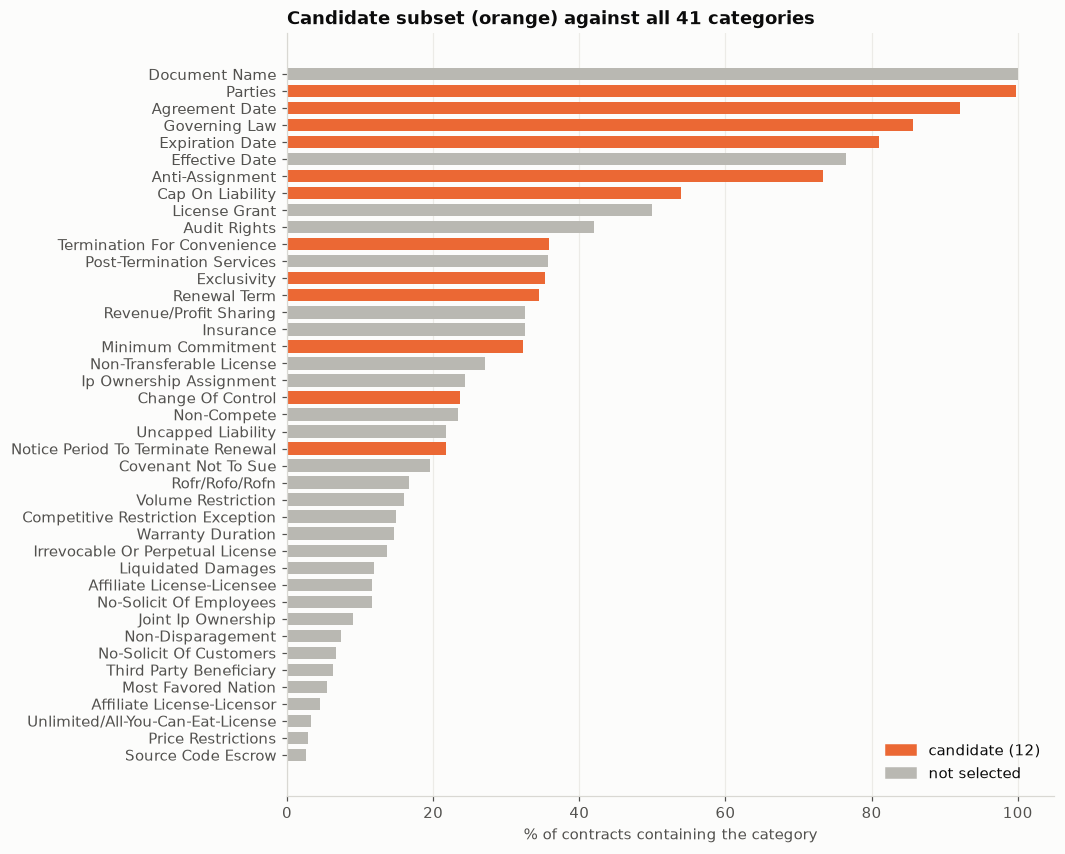

In [22]:
cand = support.loc[CANDIDATES, ["contracts", "pct_contracts", "spans", "med_span_chars"]].copy()
cand["answer_kind"] = cand.index.map(K.set_index("category").answer_kind)
display(cand.style.format({"pct_contracts": "{:.0%}", "med_span_chars": "{:.0f}", "contracts": "{:.0f}", "spans": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(9, 9))
s = support.pct_contracts.sort_values()
colors = [ORANGE if c in CANDIDATES else GREY for c in s.index]
ax.barh(s.index, s.values * 100, color=colors, height=0.72)
ax.set_title("Candidate subset (orange) against all 41 categories"); ax.set_xlabel("% of contracts containing the category")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="candidate (12)"), Patch(color=GREY, label="not selected")], loc="lower right", frameon=False)
plt.show()

## Step 12: Preview of a contract-level split
We split **by contract**, so no chunk of a test contract is ever seen in training. That is the main defence against
measuring memorization instead of learning. This preview uses a seeded 70/15/15 split stratified by contract type, and
checks that every candidate category keeps enough positive contracts in validation and test.
(The CUAD authors' own split is in `data.zip` in the GitHub repo. We may adopt it instead, to stay comparable with the paper.)

In [23]:
rng = np.random.default_rng(SEED)
split = {}
for t, g in C.groupby(C.type.fillna("Unknown")):
    names = g.contract.to_numpy().copy(); rng.shuffle(names)
    n_te = max(1, round(len(names) * .15)); n_va = max(1, round(len(names) * .15)) if len(names) >= 3 else 0
    for i, n in enumerate(names):
        split[n] = "test" if i < n_te else "val" if i < n_te + n_va else "train"
C["split"] = C.contract.map(split)
print(C.split.value_counts().to_dict())

pos = (S[S.category.isin(CANDIDATES)].assign(split=lambda x: x.contract.map(split))
         .groupby(["category", "split"]).contract.nunique().unstack(fill_value=0)[["train", "val", "test"]])
pos = pos.loc[CANDIDATES]
pos["test_ok (>=15)"] = np.where(pos.test >= 15, "yes", "LOW")
pos

{'train': 350, 'val': 80, 'test': 80}


split,train,val,test,test_ok (>=15)
category,,,,
Parties,350,79,80,yes
Agreement Date,330,71,69,yes
Expiration Date,287,62,64,yes
Renewal Term,129,26,21,yes
Notice Period To Terminate Renewal,87,13,11,LOW
Governing Law,305,66,66,yes
Termination For Convenience,127,27,29,yes
Anti-Assignment,255,62,57,yes
Change Of Control,78,21,22,yes


## Summary: key numbers

In [24]:
summary = {
    "contracts": len(C),
    "contract types": C.type.nunique(),
    "median contract length (≈tokens)": int(C.approx_tokens.median()),
    "contracts > 8k tokens": f"{(C.approx_tokens > 8000).mean():.0%}",
    "categories": len(CATS),
    "labeled spans": len(S),
    "'no answer' (contract, category) pairs": f"{(Q.n_spans == 0).mean():.0%}",
    "categories in <10% of contracts": int((support.pct_contracts < .10).sum()),
    "offset alignment": f"{S.aligned.mean():.2%}",
    "candidate categories": len(CANDIDATES),
    "candidate spans": int(S.category.isin(CANDIDATES).sum()),
}
pd.Series(summary).to_frame("value")

,value
contracts,510
contract types,25
median contract length (≈tokens),8285
contracts > 8k tokens,52%
categories,41
labeled spans,13823
"'no answer' (contract, category) pairs",68%
categories in <10% of contracts,9
offset alignment,100.00%
candidate categories,12


### Takeaways for the fine-tuning design
Observed on the first full run. Re-check them if the data or `CANDIDATES` change.

**Label quality is high, so the JSON is the source of truth.**
- Offsets are 100% aligned, the JSON context equals the `.txt` file for all 510 contracts, there are no duplicate spans, and `is_impossible` is always consistent.
- `master_clauses.csv` disagrees with the JSON for about 3% of (contract, category) pairs, because it glues non-contiguous fragments with `<omitted>`. Take spans from the JSON and only the normalized answers from the CSV.

**Contracts are long, so chunking is mandatory.**
- Median length is about 8.3k tokens; 52% are over 8k and about 10% are over 32k.
- The longest labeled span is about 3.9k chars (~1k tokens). Chunks of about 1.5k tokens (6,000 chars, 800 overlap) cut only about 0.1% of candidate spans and give about 5.3k chunks.
- About 44% of those chunks contain at least one candidate span.

**"Nothing here" is the majority answer.**
- 68% of (contract, category) questions have no span, and within a chunk most categories are empty.
- The output format must make empty a first-class answer (`[]`), and the metric must penalize false positives.
- This is also where hallucination shows up: a confident span for a clause that isn't there.

**There is a positional shortcut.**
- Document Name, Parties and Agreement Date sit in the first 5% of the contract in about 85% of cases. Governing Law and Anti-Assignment cluster near the end.
- A chunked model will see the "header" categories almost only in chunk 0. Report metrics per category, and don't let these easy categories inflate the average.

**Labels overlap, and the boundaries are the hard part.**
- The same text carries several labels: Agreement/Effective Date (265 pairs), Cap On/Uncapped Liability (141), Renewal Term/Notice Period (105), Anti-Assignment/Change Of Control (34).
- The output must allow one span under several keys. These confusable pairs are exactly where fine-tuning should beat zero-shot.

**The long tail is too thin.**
- 9 categories appear in under 10% of contracts. Exclude them; they can't be measured on a held-out split.

**The normalized answers are noisy.**
- They contain `perpetual` vs `Perpetual`, partial dates like `[]/[]/2020`, and 2 cases of "Yes" with no span.
- If we train on span plus normalized value, add a cleaning and canonicalization step first.

**The text is noisy too.**
- 22% of contracts have `[***]` redactions, 27% have repeated `Source: …` page headers, and nearly all have runs of blank lines. Gold spans themselves contain runs of spaces.
- Any whitespace normalization must be applied identically to text and spans, or the verbatim-substring hallucination check breaks.

**The split is workable, with one weak category.**
- A seeded contract-level 350/80/80 split leaves at least 20 test contracts for 11 of 12 candidates.
- Notice Period To Terminate Renewal has only 11, so either report it with a caveat, merge it with Renewal Term, or adopt the CUAD authors' split.

**There is enough supplier-relevant data.**
- 172 contracts (34%) are supply, manufacturing, distribution, outsourcing, transport, reseller, maintenance or service agreements.
- That is enough to also report a "supplier contracts only" slice of the test set.